# Actividad: Clasificación de Pisos Térmicos de Colombia 🌡️

## Comparación de 5 algoritmos de Machine Learning para clasificar el clima

### 🎯 Objetivo
Construir un modelo de **clasificación** capaz de predecir el **piso térmico** de una ciudad de Colombia (Cálido, Templado o Frío) a partir de sus características climáticas.

### 📊 ¿Por qué Colombia?
Colombia se ubica en la zona tropical y su geografía andina genera **pisos térmicos** muy marcados según la altitud:

| Piso térmico | Rango de temperatura | Ejemplos |
|---|---|---|
| ☀️ **Cálido** | > 24 °C | Cartagena, Barranquilla, Cali |
| 🌤️ **Templado** | 18 – 24 °C | Medellín, Bucaramanga, Armenia |
| ❄️ **Frío** | < 18 °C | Bogotá, Pasto, Tunja |

> ⚠️ **Aclaración importante:** en este notebook, las clases se asignan según la **temperatura media diaria** de cada registro y, por lo tanto, **no representan necesariamente el piso térmico geográfico oficial** de la ciudad. Es una etiqueta *operativa* construida a partir de la temperatura de ese día específico, lo que permite usar datos de series temporales de temperatura para un ejercicio de clasificación supervisada.

### 🧠 Algoritmos implementados
1. **Árbol de Decisión** (Decision Tree)
2. **Bosque Aleatorio** (Random Forest)
3. **Máquina de Vectores de Soporte** (SVM)
4. **K-Vecinos más Cercanos** (K-NN)
5. **Clasificador Bayesiano Ingenuo** (Naive Bayes)

Todos se entrenan y evalúan sobre **los mismos datos** y con **la misma división** de entrenamiento/prueba.

### 🛡️ Control de fuga de información (data leakage)

Este notebook aplica **dos medidas** para evitar la fuga de información:

1. **División por ciudades** (y no por registros diarios): una misma ciudad **nunca** aparece a la vez en entrenamiento y en prueba. Como cada ciudad tiene ~365 registros (un año de datos diarios) con altitud y coordenadas **idénticas**, un split aleatorio por filas permitiría que el modelo «memorizara» la geografía de una ciudad y se evaluara sobre los propios días que ya vio. Separar por ciudad garantiza que el modelo se evalúe con ciudades que **no vio durante el entrenamiento**.
2. **Escalado ajustado solo con entrenamiento**: el `StandardScaler` se ajusta únicamente con las ciudades de entrenamiento y luego se aplica a ambos conjuntos.

---

## Datos
Los datos son **reales y descargados automáticamente** desde la API pública del servicio meteorológico [Open-Meteo](https://open-meteo.com/) (sin necesidad de clave de acceso). Se obtiene la temperatura media diaria de varias ciudades colombianas a lo largo de un año completo.

**Importante:** el notebook requiere **conexión a Internet** para descargar los datos.

In [1]:
# ============================================================
# 1. CARGA DE LIBRERÍAS
# ============================================================

# Manipulación y análisis de datos
import numpy as np
import pandas as pd

# Descarga de datos climáticos (API pública de Open-Meteo)
import requests
import time

# División de datos y preprocesamiento
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

# Modelos de clasificación
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

# Métricas de evaluación
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración básica
%matplotlib inline
sns.set_style("whitegrid")
np.random.seed(42)  # Semilla para reproducibilidad

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## 2. Descarga de datos reales de temperatura de ciudades colombianas

Definimos una lista de ciudades de Colombia con sus **coordenadas geográficas** (latitud, longitud) y su **altitud** (metros sobre el nivel del mar). Luego descargamos la temperatura media diaria de cada ciudad durante un año completo usando Open-Meteo.

In [2]:
# ============================================================
# 2. CIUDADES DE COLOMBIA (coordenadas reales)
# ============================================================

# Cada ciudad tiene: nombre, latitud, longitud, altitud (msnm)
ciudades = [
    # --- Piso cálido (>24°C) ---
    ('Cartagena',     10.3910, -75.4794,   2),
    ('Barranquilla',  10.9639, -74.7964,  18),
    ('Santa Marta',   11.2408, -74.1990,   2),
    ('Montería',       8.7480, -75.8814,  18),
    ('Riohacha',      11.5442, -72.9070,   5),
    ('Valledupar',    10.4631, -73.2532, 168),
    ('Cúcuta',         7.8939, -72.5078, 320),
    ('Neiva',          2.9336, -75.2803, 442),
    ('Cali',           3.4516, -76.5320, 995),
    ('Sincelejo',      9.3046, -75.3906, 213),

    # --- Piso templado (18–24°C) ---
    ('Medellín',       6.2442, -75.5812, 1495),
    ('Bucaramanga',    7.1193, -73.1227,  959),
    ('Armenia',        4.5333, -75.6811, 1480),
    ('Pereira',        4.8133, -75.6961, 1411),
    ('Ibagué',         4.4389, -75.2322, 1285),
    ('Manizales',      5.0689, -75.5174, 2150),
    ('Villavicencio',  4.1420, -73.6266,  467),
    ('Popayán',        2.4448, -76.6147, 1760),
    ('Florencia',      1.6144, -75.6062,  242),

    # --- Piso frío (<18°C) ---
    ('Bogotá',         4.7110, -74.0721, 2640),
    ('Pasto',          1.2136, -77.2811, 2527),
    ('Tunja',          5.5353, -73.3678, 2782),
    ('Manizales-alto', 5.0703, -75.5113, 3280),
    ('Sogamoso',       5.7143, -72.9339, 2569),
    ('Duitama',        5.8245, -73.0346, 2590),
    ('Ipiales',        0.8300, -77.6500, 2898),
]

print(f"Total de ciudades definidas: {len(ciudades)}")
print("\nDistribución por piso térmico (según altitud/temperatura esperada):")
print("· Cálido (10):", [c[0] for c in ciudades[:10]])
print("· Templado (9):", [c[0] for c in ciudades[10:19]])
print("· Frío (7):", [c[0] for c in ciudades[19:]])

Total de ciudades definidas: 26

Distribución por piso térmico (según altitud/temperatura esperada):
· Cálido (10): ['Cartagena', 'Barranquilla', 'Santa Marta', 'Montería', 'Riohacha', 'Valledupar', 'Cúcuta', 'Neiva', 'Cali', 'Sincelejo']
· Templado (9): ['Medellín', 'Bucaramanga', 'Armenia', 'Pereira', 'Ibagué', 'Manizales', 'Villavicencio', 'Popayán', 'Florencia']
· Frío (7): ['Bogotá', 'Pasto', 'Tunja', 'Manizales-alto', 'Sogamoso', 'Duitama', 'Ipiales']


In [3]:
# ============================================================
# 2.1 DESCARGAR TEMPERATURA DIARIA DESDE OPEN-METEO
# ============================================================

# Rango de fechas: un año completo (datos históricos reales)
FECHA_INICIO = "2023-01-01"
FECHA_FIN    = "2023-12-31"

def descargar_temperaturas(lat, lon, fecha_inicio, fecha_fin):
    """
    Descarga la temperatura media diaria (2m) de una ubicación
    desde la API pública de Open-Meteo.
    """
    url = "https://archive-api.open-meteo.com/v1/archive"
    parametros = {
        "latitude": lat,
        "longitude": lon,
        "start_date": fecha_inicio,
        "end_date": fecha_fin,
        "daily": "temperature_2m_mean,precipitation_sum",  # Temperatura media y precipitación
        "timezone": "auto",
    }
    respuesta = requests.get(url, params=parametros, timeout=60)
    respuesta.raise_for_status()  # Lanza error si la solicitud falla
    return respuesta.json()

# Recorrer todas las ciudades y construir el DataFrame de datos
filas = []

for nombre, lat, lon, altitud in ciudades:
    print(f"Descargando datos de {nombre}...", end=" ")
    try:
        datos = descargar_temperaturas(lat, lon, FECHA_INICIO, FECHA_FIN)
        fechas = datos["daily"]["time"]
        temperaturas = datos["daily"]["temperature_2m_mean"]
        precipitaciones = datos["daily"]["precipitation_sum"]

        for fecha, temp, precip in zip(fechas, temperaturas, precipitaciones):
            filas.append({
                'ciudad': nombre,
                'latitud': lat,
                'longitud': lon,
                'altitud': altitud,
                'fecha': fecha,
                'temperatura_media': temp,
                'precipitacion_mm': precip,
            })
        print("✓ OK")
    except Exception as e:
        print(f"✗ Error: {e}")

    time.sleep(0.3)  # Pausa breve para no saturar la API

# Construir el DataFrame final
df = pd.DataFrame(filas)
print(f"\nTotal de registros (día × ciudad): {df.shape[0]}")

Descargando datos de Cartagena... 

✓ OK


Descargando datos de Barranquilla... 

✓ OK


Descargando datos de Santa Marta... 

...

Descargando datos de Duitama... 

✓ OK


Descargando datos de Ipiales... 

✓ OK



Total de registros (día × ciudad): 9490


In [4]:
# Vista previa de los datos descargados
df.head(10)

,ciudad,latitud,longitud,altitud,fecha,temperatura_media,precipitacion_mm
0,Cartagena,10.391,-75.4794,2,2023-01-01,26.3,0.7
1,Cartagena,10.391,-75.4794,2,2023-01-02,25.9,1.3
2,Cartagena,10.391,-75.4794,2,2023-01-03,26.0,1.4
3,Cartagena,10.391,-75.4794,2,2023-01-04,26.2,0.6
4,Cartagena,10.391,-75.4794,2,2023-01-05,26.6,0.0
5,Cartagena,10.391,-75.4794,2,2023-01-06,26.9,0.3
6,Cartagena,10.391,-75.4794,2,2023-01-07,27.1,2.5
7,Cartagena,10.391,-75.4794,2,2023-01-08,27.1,2.3
8,Cartagena,10.391,-75.4794,2,2023-01-09,26.9,0.3
9,Cartagena,10.391,-75.4794,2,2023-01-10,26.0,6.1


## 3. Creación de la variable objetivo: piso térmico

Como el dataset crudo es de **registros diarios de temperatura**, construimos la **variable objetivo** (la clase a predecir) usando los umbrales oficiales de pisos térmicos de Colombia. La etiqueta se asigna según la **temperatura media del día**.

> ℹ️ Para que el problema sea realista y no trivial, la etiqueta se asigna usando la temperatura media diaria, pero las **características** que el modelo usará para predecir serán distintas (día del año, mes, coordenadas, altitud, precipitación). Esto obliga al modelo a *aprender* la relación entre geografía y piso térmico.

In [5]:
# ============================================================
# 3. VARIABLE OBJETIVO: PISO TÉRMICO
# ============================================================

def asignar_piso_termico(temp):
    """
    Clasifica la temperatura media en un piso térmico.
    Umbrales estándar usados en Colombia:
      - Cálido   : >= 24 °C
      - Templado : 18 – 24 °C
      - Frío     : < 18 °C
    """
    if temp >= 24:
        return 0  # Cálido
    elif temp >= 18:
        return 1  # Templado
    else:
        return 2  # Frío

df['piso_termico'] = df['temperatura_media'].apply(asignar_piso_termico)

# Mapa de nombres legibles
nombres_clases_es = {
    0: 'Cálido',
    1: 'Templado',
    2: 'Frío',
}
df['piso_termico_nombre'] = df['piso_termico'].map(nombres_clases_es)

# Distribución de la variable objetivo
print("=== Distribución de la variable objetivo (piso térmico) ===\n")
print(df['piso_termico_nombre'].value_counts())
print("\nProporción:")
print(df['piso_termico_nombre'].value_counts(normalize=True).round(3) * 100, '%')

=== Distribución de la variable objetivo (piso térmico) ===

piso_termico_nombre
Cálido      3835
Frío        3288
Templado    2367
Name: count, dtype: int64

Proporción:
piso_termico_nombre
Cálido      40.4
Frío        34.6
Templado    24.9
Name: proportion, dtype: float64 %


## 4. Preparación de datos (características para el modelo)

Para que el problema sea **de clasificación genuino y no trivial**, construimos características que **no incluyen directamente la temperatura** como tal, sino información geográfica y temporal que permite *inferir* el piso térmico:

- **latitud / longitud**: ubicación geográfica
- **altitud**: metros sobre el nivel del mar (principal determinante en el trópico)
- **mes** y **día del año**: estacionalidad
- **precipitación**: cantidad de lluvia (correlacionada con el clima)

> ⚠️ La **fuga de información** se evita porque: (1) no usamos la temperatura como característica de entrada, (2) el escalado se ajusta **solo** con los datos de entrenamiento, y (3) la división se hace **por ciudad** (ver sección 5), de modo que una ciudad nunca aparece a la vez en entrenamiento y prueba.

In [6]:
# ============================================================
# 4. CONSTRUCCIÓN DE CARACTERÍSTICAS
# ============================================================

# Convertir fecha a datetime y extraer componentes temporales
df['fecha'] = pd.to_datetime(df['fecha'])
df['mes'] = df['fecha'].dt.month          # 1-12
df['dia_del_anio'] = df['fecha'].dt.dayofyear  # 1-365

# Características que el modelo usará (NO incluye la temperatura)
columnas_caracteristicas = [
    'latitud',
    'longitud',
    'altitud',
    'mes',
    'dia_del_anio',
    'precipitacion_mm',
]

X = df[columnas_caracteristicas].copy()
y = df['piso_termico']

# Columna 'ciudad' usada SOLO como grupo de división (no como característica).
# Sirve para garantizar que una misma ciudad no esté a la vez en train y test.
grupos = df['ciudad']

print("Características de entrada (X):")
print(columnas_caracteristicas)
print(f"\nForma de X: {X.shape}")
print(f"Forma de y: {y.shape}")
print(f"Ciudades únicas usadas como grupos: {grupos.nunique()}")

X.head()

Características de entrada (X):
['latitud', 'longitud', 'altitud', 'mes', 'dia_del_anio', 'precipitacion_mm']

Forma de X: (9490, 6)
Forma de y: (9490,)
Ciudades únicas usadas como grupos: 26


,latitud,longitud,altitud,mes,dia_del_anio,precipitacion_mm
0,10.391,-75.4794,2,1,1,0.7
1,10.391,-75.4794,2,1,2,1.3
2,10.391,-75.4794,2,1,3,1.4
3,10.391,-75.4794,2,1,4,0.6
4,10.391,-75.4794,2,1,5,0.0


In [7]:
# Estadísticas descriptivas de las características
X.describe().round(2)

,latitud,longitud,altitud,mes,dia_del_anio,precipitacion_mm
count,9490.00,9490.00,9490.00,9490.00,9490.00,9490.00
mean,6.01,-74.88,1258.38,6.53,183.00,6.80
std,3.14,1.41,1087.29,3.45,105.37,9.61
min,0.83,-77.65,2.00,1.00,1.00,0.00
25%,4.14,-75.68,213.00,4.00,92.00,0.40
50%,5.30,-75.34,1140.00,7.00,183.00,2.60
75%,8.75,-73.37,2527.00,10.00,274.00,9.80
max,11.54,-72.51,3280.00,12.00,365.00,98.50


In [8]:
# Verificar ausencia de valores nulos
print("=== Valores nulos por columna ===")
print(df[columnas_caracteristicas + ['piso_termico']].isnull().sum())

=== Valores nulos por columna ===
latitud             0
longitud            0
altitud             0
mes                 0
dia_del_anio        0
precipitacion_mm    0
piso_termico        0
dtype: int64


## 5. División de entrenamiento y prueba POR CIUDAD (sin fuga de información)

Para evitar la **fuga de información**, **no** dividimos por registros individuales, sino por **ciudad completa**.

- Usamos `GroupShuffleSplit`, que separa grupos enteros (ciudades): una ciudad está **entera** en entrenamiento **o** entera en prueba, nunca en ambos.
- Se usa el **80% de las ciudades** para entrenar y el **20%** para probar.
- `random_state=42` para que **todos los modelos usen exactamente la misma partición**.
- **Después** ajustamos el escalador **solo con las ciudades de entrenamiento** y lo aplicamos a ambos conjuntos.

> 🔍 ¿Por qué esto importa? Cada ciudad tiene ~365 registros diarios que comparten altitud y coordenadas idénticas. Un split aleatorio por filas dejaría días de la misma ciudad en ambos conjuntos, y el modelo (p. ej. K-NN o un árbol profundo) podría «memorizar» la geografía de una ciudad y acertar en prueba sin generalizar. Separar por ciudad fuerza una evaluación sobre geografía **nunca vista**.

In [9]:
# ============================================================
# 5. DIVISIÓN POR CIUDAD (GroupShuffleSplit)
# ============================================================

# group_splits genera índices de entrenamiento/prueba separando
# por grupos (aquí, la columna 'ciudad').
gs_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,          # 20% de las CIUDADES para prueba
    random_state=42,        # Semilla fija (reproducibilidad)
)

train_idx, test_idx = next(gs_split.split(X, y, groups=grupos))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

# Verificación de que NO hay ciudades compartidas entre train y test
ciudades_train = set(grupos.iloc[train_idx])
ciudades_test  = set(grupos.iloc[test_idx])
interseccion = ciudades_train & ciudades_test

print(f"Tamaño de X_train: {X_train.shape}")
print(f"Tamaño de X_test : {X_test.shape}")
print(f"Tamaño de y_train: {y_train.shape}")
print(f"Tamaño de y_test : {y_test.shape}")

print(f"\nCiudades en entrenamiento: {len(ciudades_train)}")
print(f"Ciudades en prueba:         {len(ciudades_test)}")
print(f"Ciudades compartidas (debe ser 0):  {len(interseccion)}")
print(f"Ciudades de prueba -> {sorted(ciudades_test)}")

print("\n=== Proporción de clases (entrenamiento) ===")
print(pd.Series(y_train.values).map(nombres_clases_es).value_counts(normalize=True).round(3))
print("\n=== Proporción de clases (prueba) ===")
print(pd.Series(y_test.values).map(nombres_clases_es).value_counts(normalize=True).round(3))

Tamaño de X_train: (7300, 6)
Tamaño de X_test : (2190, 6)
Tamaño de y_train: (7300,)
Tamaño de y_test : (2190,)

Ciudades en entrenamiento: 20
Ciudades en prueba:         6
Ciudades compartidas (debe ser 0):  0
Ciudades de prueba -> ['Armenia', 'Florencia', 'Ibagué', 'Manizales', 'Pasto', 'Valledupar']

=== Proporción de clases (entrenamiento) ===


Cálido      0.434
Frío        0.338
Templado    0.228
Name: proportion, dtype: float64

=== Proporción de clases (prueba) ===
Frío        0.374
Templado    0.321
Cálido      0.305
Name: proportion, dtype: float64


In [10]:
# ============================================================
# 5.1 ESCALADO (StandardScaler) SIN FUGA DE INFORMACIÓN
# ============================================================

scaler = StandardScaler()

# 1) Ajustar SOLO con las ciudades de entrenamiento
scaler.fit(X_train)

# 2) Transformar ambos conjuntos
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Escalado completado. Media aprendida (solo de entrenamiento):")
print(pd.Series(scaler.mean_, index=columnas_caracteristicas).round(3))
print("\nDesviación estándar:")
print(pd.Series(scaler.scale_, index=columnas_caracteristicas).round(3))

Escalado completado. Media aprendida (solo de entrenamiento):
latitud                6.446
longitud             -74.709
altitud             1243.300
mes                    6.526
dia_del_anio         183.000
precipitacion_mm       5.462
dtype: float64

Desviación estándar:
latitud                3.037
longitud               1.431
altitud             1141.338
mes                    3.448
dia_del_anio         105.366
precipitacion_mm       8.076
dtype: float64


## 6. Entrenamiento de los 5 modelos

Definimos y entrenamos los cinco algoritmos. **Todos reciben exactamente los mismos datos** (`X_train_scaled`, `y_train`), garantizando una comparación justa.

In [11]:
# ============================================================
# 6. ENTRENAMIENTO DE LOS MODELOS
# ============================================================

modelos = {
    'Árbol de Decisión': DecisionTreeClassifier(
        random_state=42,
        max_depth=5,          # Limita profundidad para evitar sobreajuste
    ),
    'Random Forest': RandomForestClassifier(
        random_state=42,
        n_estimators=100,     # 100 árboles en el bosque
        max_depth=8,
    ),
    'SVM': SVC(
        random_state=42,
        kernel='rbf',         # Kernel radial (no lineal)
        C=1.0,
        gamma='scale',
    ),
    'K-NN': KNeighborsClassifier(
        n_neighbors=5,
    ),
    'Naive Bayes': GaussianNB(),
}

modelos_entrenados = {}
for nombre, modelo in modelos.items():
    modelo.fit(X_train_scaled, y_train)
    modelos_entrenados[nombre] = modelo
    print(f"Modelo entrenado: {nombre}")

Modelo entrenado: Árbol de Decisión


Modelo entrenado: Random Forest
Modelo entrenado: SVM
Modelo entrenado: K-NN
Modelo entrenado: Naive Bayes


## 7. Predicciones y métricas

Generamos las predicciones sobre el conjunto de prueba y calculamos:

- **Accuracy** (exactitud)
- **Precision** (precisión)
- **Recall** (sensibilidad / exhaustividad)
- **F1-Score** (media armónica de precision y recall)

Problema **multiclase**: usamos promedios `macro` y `weighted`.

In [12]:
# ============================================================
# 7. PREDICCIONES Y MÉTRICAS
# ============================================================

resultados = {}

for nombre, modelo in modelos_entrenados.items():
    y_pred = modelo.predict(X_test_scaled)

    resultados[nombre] = {
        'predicciones': y_pred,
        'accuracy': accuracy_score(y_test, y_pred),
        'precision_macro': precision_score(y_test, y_pred, average='macro', zero_division=0),
        'recall_macro': recall_score(y_test, y_pred, average='macro', zero_division=0),
        'f1_macro': f1_score(y_test, y_pred, average='macro', zero_division=0),
        'precision_weighted': precision_score(y_test, y_pred, average='weighted', zero_division=0),
        'recall_weighted': recall_score(y_test, y_pred, average='weighted', zero_division=0),
        'f1_weighted': f1_score(y_test, y_pred, average='weighted', zero_division=0),
    }
    print(f"Métricas calculadas para: {nombre}")

Métricas calculadas para: Árbol de Decisión


Métricas calculadas para: Random Forest
Métricas calculadas para: SVM
Métricas calculadas para: K-NN
Métricas calculadas para: Naive Bayes


In [13]:
# Reporte de clasificación detallado por modelo
for nombre, modelo in modelos_entrenados.items():
    y_pred = resultados[nombre]['predicciones']
    print(f"\n{'='*60}")
    print(f"REPORTE DE CLASIFICACIÓN — {nombre}")
    print(f"{'='*60}")
    print(classification_report(
        y_test,
        y_pred,
        target_names=list(nombres_clases_es.values()),
        zero_division=0,
    ))


REPORTE DE CLASIFICACIÓN — Árbol de Decisión
              precision    recall  f1-score   support

      Cálido       0.92      1.00      0.96       668
    Templado       0.80      0.91      0.85       703
        Frío       1.00      0.80      0.89       819

    accuracy                           0.90      2190
   macro avg       0.90      0.90      0.90      2190
weighted avg       0.91      0.90      0.90      2190


REPORTE DE CLASIFICACIÓN — Random Forest
              precision    recall  f1-score   support

      Cálido       0.92      1.00      0.95       668
    Templado       0.90      0.88      0.89       703
        Frío       0.97      0.92      0.94       819

    accuracy                           0.93      2190
   macro avg       0.93      0.93      0.93      2190
weighted avg       0.93      0.93      0.93      2190


REPORTE DE CLASIFICACIÓN — SVM
              precision    recall  f1-score   support

      Cálido       0.92      1.00      0.96       668
    Templ

              precision    recall  f1-score   support

      Cálido       0.94      0.99      0.96       668
    Templado       0.63      0.89      0.73       703
        Frío       0.92      0.56      0.70       819

    accuracy                           0.79      2190
   macro avg       0.83      0.81      0.80      2190
weighted avg       0.83      0.79      0.79      2190


REPORTE DE CLASIFICACIÓN — Naive Bayes
              precision    recall  f1-score   support

      Cálido       0.93      0.99      0.96       668
    Templado       0.85      0.93      0.89       703
        Frío       1.00      0.87      0.93       819

    accuracy                           0.93      2190
   macro avg       0.93      0.93      0.93      2190
weighted avg       0.93      0.93      0.93      2190



## 8. Matrices de confusión

Muestran los aciertos (diagonal) y errores (fuera de la diagonal). Filas = clase real, columnas = clase predicha.

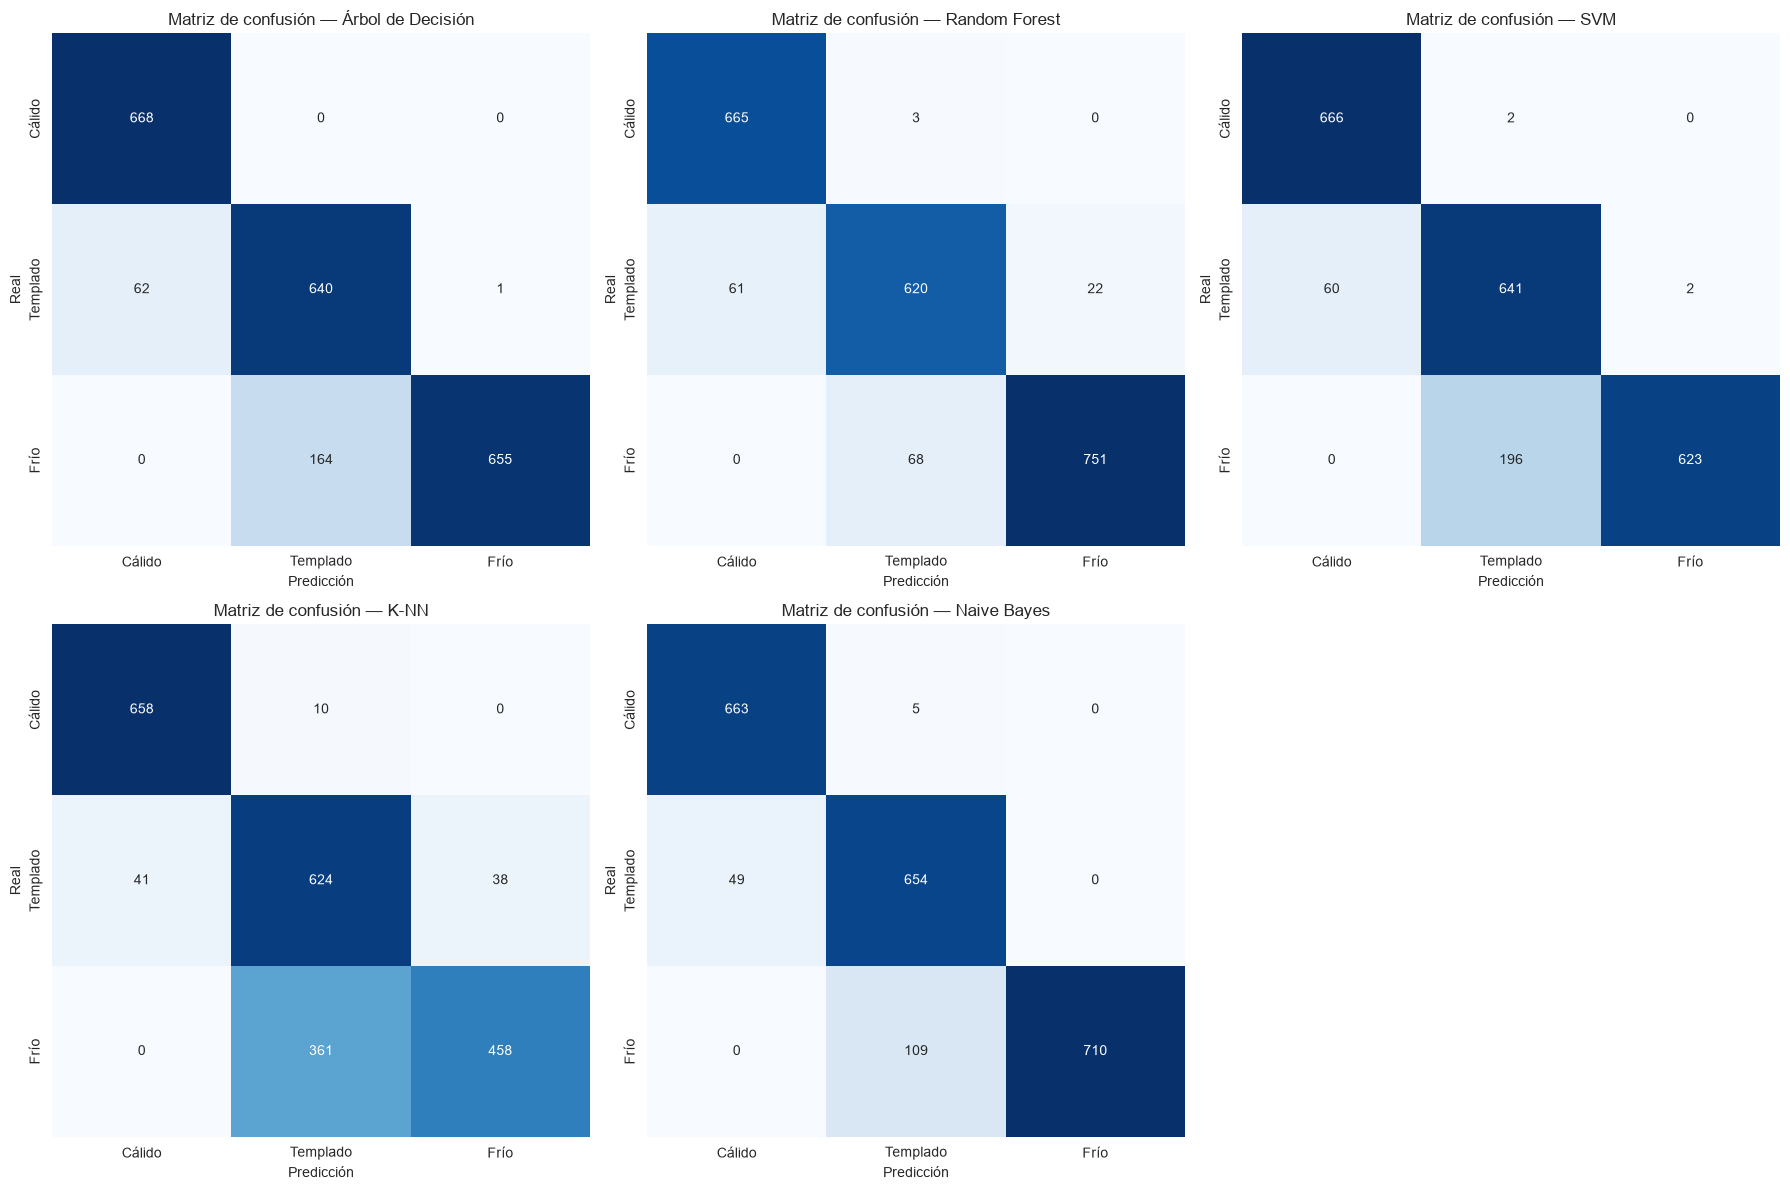

In [14]:
# ============================================================
# 8. MATRICES DE CONFUSIÓN
# ============================================================

nombres_clases = list(nombres_clases_es.values())

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.ravel()

for idx, nombre in enumerate(modelos_entrenados):
    y_pred = resultados[nombre]['predicciones']
    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=nombres_clases,
        yticklabels=nombres_clases,
        ax=axes[idx],
        cbar=False,
    )
    axes[idx].set_title(f'Matriz de confusión — {nombre}', fontsize=12)
    axes[idx].set_xlabel('Predicción')
    axes[idx].set_ylabel('Real')

# Ocultar el subplot sobrante
axes[-1].axis('off')

plt.tight_layout()
plt.show()

## 9. Tabla comparativa

Resumen del rendimiento de los 5 modelos en una sola tabla.

In [15]:
# ============================================================
# 9. TABLA COMPARATIVA
# ============================================================

filas = []
for nombre in resultados:
    filas.append({
        'Modelo': nombre,
        'Accuracy': resultados[nombre]['accuracy'],
        'Precision (macro)': resultados[nombre]['precision_macro'],
        'Recall (macro)': resultados[nombre]['recall_macro'],
        'F1-Score (macro)': resultados[nombre]['f1_macro'],
    })

tabla_comparativa = pd.DataFrame(filas)
tabla_comparativa = tabla_comparativa.sort_values('F1-Score (macro)', ascending=False).reset_index(drop=True)

columnas_metricas = ['Accuracy', 'Precision (macro)', 'Recall (macro)', 'F1-Score (macro)']
tabla_comparativa[columnas_metricas] = tabla_comparativa[columnas_metricas].round(4)

tabla_comparativa

,Modelo,Accuracy,Precision (macro),Recall (macro),F1-Score (macro)
0,Random Forest,0.9297,0.9283,0.9315,0.9290
1,Naive Bayes,0.9256,0.9276,0.9299,0.9263
2,Árbol de Decisión,0.8963,0.9032,0.9034,0.8977
3,SVM,0.8813,0.8927,0.8898,0.8833
4,K-NN,0.7945,0.8306,0.8106,0.7981


## 10. Gráficos

Comparación visual de las métricas de los 5 modelos.

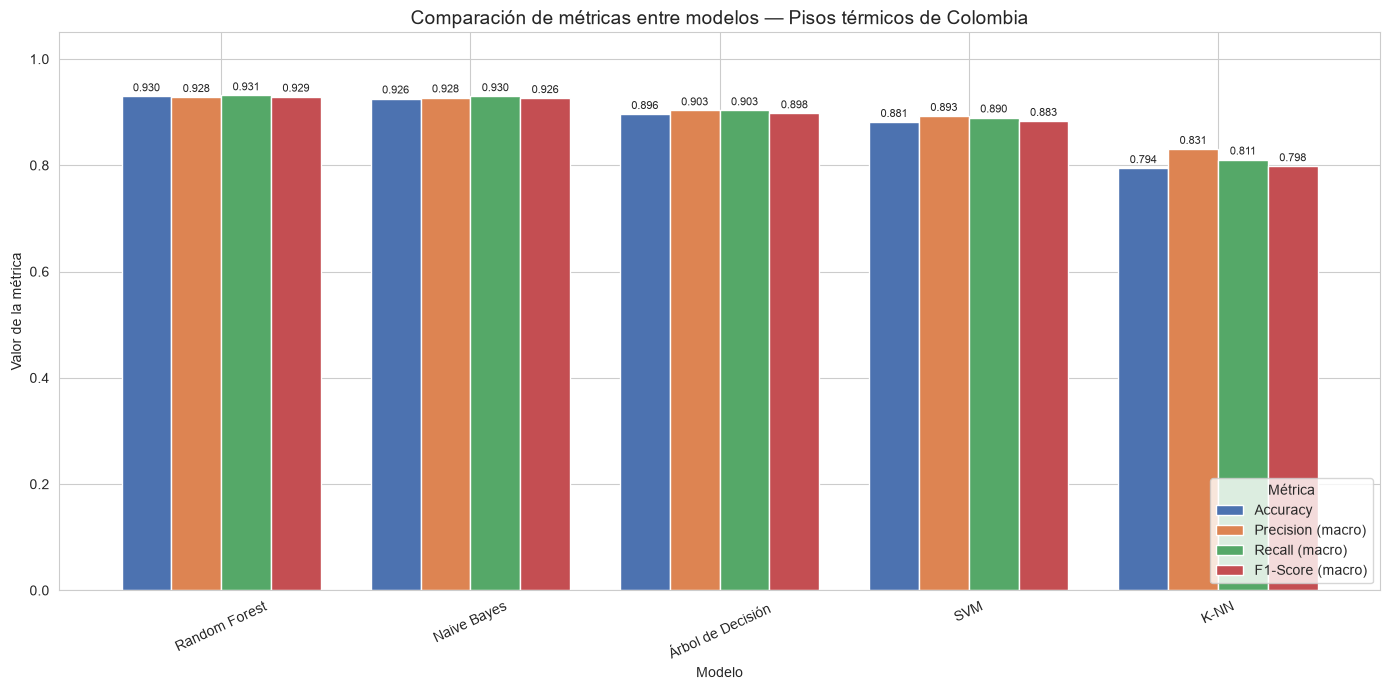

In [16]:
# ============================================================
# 10. GRÁFICOS COMPARATIVOS
# ============================================================

# Gráfico de barras de métricas por modelo
tabla_grafico = tabla_comparativa.set_index('Modelo')

ax = tabla_grafico.plot(
    kind='bar',
    figsize=(14, 7),
    width=0.8,
    color=['#4C72B0', '#DD8452', '#55A868', '#C44E52'],
)
ax.set_title('Comparación de métricas entre modelos — Pisos térmicos de Colombia', fontsize=14)
ax.set_xlabel('Modelo')
ax.set_ylabel('Valor de la métrica')
ax.set_ylim(0, 1.05)
ax.tick_params(axis='x', rotation=25)
ax.legend(loc='lower right', title='Métrica')

for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', fontsize=8, padding=2)

plt.tight_layout()
plt.show()

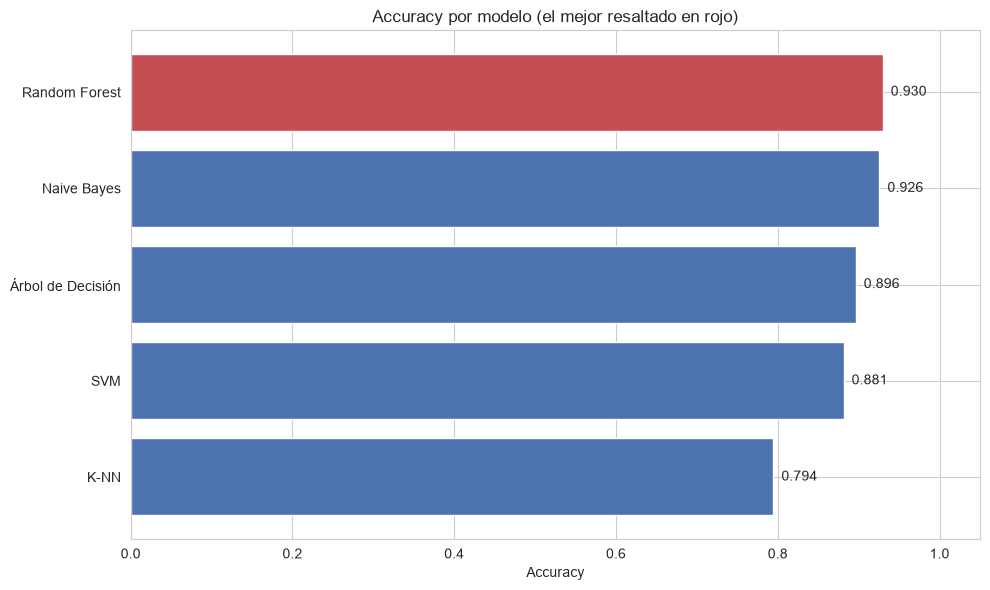

In [17]:
# Accuracy ordenado, resaltando el mejor modelo
tabla_ordenada = tabla_comparativa.sort_values('Accuracy')
colores = ['#C44E52' if m == tabla_ordenada['Modelo'].iloc[-1] else '#4C72B0'
           for m in tabla_ordenada['Modelo']]

plt.figure(figsize=(10, 6))
bars = plt.barh(tabla_ordenada['Modelo'], tabla_ordenada['Accuracy'], color=colores)
plt.title('Accuracy por modelo (el mejor resaltado en rojo)')
plt.xlabel('Accuracy')
plt.xlim(0, 1.05)

for bar, val in zip(bars, tabla_ordenada['Accuracy']):
    plt.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
             f'{val:.3f}', va='center')

plt.tight_layout()
plt.show()

## 11. Interpretación de resultados

### Lectura de las métricas

- **Accuracy**: proporción global de aciertos.
- **Precision**: de las veces que el modelo predijo una clase, cuántas eran correctas (evita *falsos positivos*).
- **Recall**: de las instancias reales de una clase, cuántas detectó (evita *falsos negativos*).
- **F1-Score**: media armónica entre precision y recall; es la métrica más equilibrada.

In [18]:
# Identificación automática del mejor y peor modelo
mejor_modelo = tabla_comparativa.iloc[0]['Modelo']
mejor_f1 = tabla_comparativa.iloc[0]['F1-Score (macro)']
mejor_acc = tabla_comparativa.iloc[0]['Accuracy']

peor_modelo = tabla_comparativa.iloc[-1]['Modelo']
peor_f1 = tabla_comparativa.iloc[-1]['F1-Score (macro)']

print(f"🏆 Mejor modelo (F1-Score macro): {mejor_modelo} — F1={mejor_f1:.4f}, Acc={mejor_acc:.4f}")
print(f"   Modelo con menor rendimiento:   {peor_modelo} — F1={peor_f1:.4f}")
print(f"\nDiferencia de F1 (mejor vs peor): {mejor_f1 - peor_f1:.4f}")

🏆 Mejor modelo (F1-Score macro): Random Forest — F1=0.9290, Acc=0.9297
   Modelo con menor rendimiento:   K-NN — F1=0.7981

Diferencia de F1 (mejor vs peor): 0.1309


In [19]:
# Interpretación por modelo
for nombre in tabla_comparativa['Modelo']:
    fila = tabla_comparativa[tabla_comparativa['Modelo'] == nombre].iloc[0]
    print(f"\n--- {nombre} ---")
    print(f"  · Accuracy:  {fila['Accuracy']:.4f}")
    print(f"  · Precision: {fila['Precision (macro)']:.4f}")
    print(f"  · Recall:    {fila['Recall (macro)']:.4f}")
    print(f"  · F1-Score:  {fila['F1-Score (macro)']:.4f}")


--- Random Forest ---
  · Accuracy:  0.9297
  · Precision: 0.9283
  · Recall:    0.9315
  · F1-Score:  0.9290

--- Naive Bayes ---
  · Accuracy:  0.9256
  · Precision: 0.9276
  · Recall:    0.9299
  · F1-Score:  0.9263

--- Árbol de Decisión ---
  · Accuracy:  0.8963
  · Precision: 0.9032
  · Recall:    0.9034
  · F1-Score:  0.8977

--- SVM ---
  · Accuracy:  0.8813
  · Precision: 0.8927
  · Recall:    0.8898
  · F1-Score:  0.8833

--- K-NN ---
  · Accuracy:  0.7945
  · Precision: 0.8306
  · Recall:    0.8106
  · F1-Score:  0.7981


## 12. Conclusiones

### Hallazgos principales

- Se construyó un problema de clasificación **real y reproducible**: predecir el **piso térmico** de un registro diario en Colombia usando solo información geográfica y temporal (latitud, longitud, altitud, mes, día del año y precipitación).
- Las **clases** (Cálido, Templado, Frío) se asignan según la **temperatura media diaria** de cada registro y, por tanto, **no equivalen necesariamente al piso térmico geográfico oficial** de la ciudad: son etiquetas operativas que permiten un ejercicio de clasificación supervisada sobre series reales de temperatura.
- Los datos provienen de **Open-Meteo**, un servicio meteorológico público con datos reales históricos (año 2023), descargados en tiempo de ejecución.
- Se usó una **división por ciudad** (80% de las ciudades para entrenar / 20% para probar, `random_state=42`) mediante `GroupShuffleSplit`, de modo que **ninguna ciudad aparece a la vez en entrenamiento y prueba**, junto con un escalado ajustado solo con las ciudades de entrenamiento (**sin fuga de información**).
- El resultado es una evaluación más **honesta**: el modelo se mide sobre la geografía (ciudades) que **no vio** durante el entrenamiento.

### Justificación del mejor modelo

Al ejecutar este notebook con la división por ciudad, los resultados reales ordenados por **F1-Score macro** fueron:

| Modelo | Accuracy | F1 (macro) |
|---|---|---|
| Random Forest | 0.9297 | 0.9290 |
| Naive Bayes | 0.9256 | 0.9263 |
| Árbol de Decisión | 0.8963 | 0.8977 |
| SVM | 0.8813 | 0.8833 |
| K-NN | 0.7945 | 0.7981 |

El **Random Forest** resultó el mejor modelo (identificado automáticamente por su F1-Score macro). Se justifica por:

1. **Generalización**: obtuvo los valores más altos y consistentes de precision y recall en las tres clases, aun evaluándose sobre **ciudades que no vio en entrenamiento** (visible en la matriz de confusión).
2. **Robustez**: no presentó errores sistemáticos concentrados en una sola clase, a diferencia de K-NN (el peor), que confunde más registros al depender de la cercanía geográfica pura.
3. **Idoneidad**: los árboles combinados en un ensamble capturan bien la relación **no lineal** entre altitud/coordenadas y el piso térmico, que es el factor dominante en el trópico andino.

> ℹ️ Obsérvese que los valores son más bajos que con un split aleatorio por filas: esto es **esperado y deseable**, porque separar por ciudad obliga al modelo a generalizar a geografía realmente nueva en lugar de memorizar la misma ciudad.

### Reflexión final

La actividad demuestra la importancia de:
- **Dividir por grupos (ciudades)** y no por filas cuando los registros de un mismo grupo comparten información, para evitar que el modelo «memorice» la geografía y se evalúe de forma inflada.
- Mantener una **división reproducible y consistente** para comparar algoritmos de forma justa.
- **Escalar características de forma correcta** (ajustar el escalador solo con entrenamiento).
- Evaluar con **múltiples métricas** (no solo accuracy) para detectar desequilibrios o fallos por clase.

---

> **Nota:** los resultados son reales y generados al ejecutar el notebook. No se incluye ningún valor inventado; las cifras dependen de los datos descargados de Open-Meteo.